In [1]:
# 基础库
import numpy as np
import xarray as xr
import os
import sys
import gc  
import pickle

# 统计分析库
import statsmodels.api as sm
from scipy.stats import norm, ttest_1samp
import pymannkendall as mk
from scipy.stats import pearsonr
from scipy.stats import linregress

# 地理空间处理库
from shapely.geometry import Point
import geopandas as gpd

# 并行处理库
from multiprocessing import Pool, cpu_count

# 可视化库
from matplotlib import gridspec, pyplot as plt
from matplotlib.lines import Line2D
from cartopy import crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.path as mpath
import matplotlib.ticker as mticker
from matplotlib.colors import Normalize
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import LinearSegmentedColormap
import warnings
import matplotlib.patches as mpatches
warnings.filterwarnings("ignore")

# 自定义模块
sys.path.append('/public/home/zhujw/work/guoly/code/Self-package/ccg_filter')
import ccg_filter

def mk_test(x):
    ## mk检验，输入时间序列W后，输出对应的标准正态值
    S = 0
    n = len(x)
    for i in range(n - 1):
        for j in range(i + 1, n):
            S += np.sign(x[j] - x[i])
    data_sort = np.sort(x)
    num = 0
    nn = 0
    for i in range(len(x) - 1):
        if data_sort[i + 1] - data_sort[i] <= 1.0e-37:
            nn += 1
        else:
            num += nn * (nn - 1) * (2 * nn + 5)
            nn = 1
    var_s = (n * (n - 1) * (2 * n + 5) - num) / 18
    if S > 0:
        Z = (S - 1) / np.sqrt(var_s)
    elif S == 0:
        Z = 0
    elif S < 0:
        Z = (S + 1) / np.sqrt(var_s)

    return Z

def trend_window(AMP, min_line, cal_type=None, mk_type=None):
#    这个函数用来计算AMP的滑动窗口趋势，或者非滑动窗口趋势
#    AMP 原始序列 min_line 滑动窗口最小数 
#    当cal_type不为空时，使用gls方法计算b
    b = []
    p = []
    x = np.arange(1, len(AMP) + 1)
    line_start = x[:len(x) - min_line + 1]
    for i in range(len(line_start)):
        AMP_now = AMP[i:i + min_line]
        x_now = np.arange(1, min_line + 1)

        if cal_type is not None:
            x_now = sm.add_constant(x_now)
            gls_model = sm.GLS(AMP_now, x_now)
            gls_results = gls_model.fit()
            params = gls_results.params
            b.append(params[1])
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
        
        else:
            b0 = np.polyfit(x_now[~np.isnan(AMP_now)], AMP_now[~np.isnan(AMP_now)], 1)  # min_square的系数
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
            b.append(b0[0])

    Z = np.vstack((p, b))
    return Z

def cal_trend_diff(data, time, min_len, trend_select, p_threshold=0.1, site=None, ratio_flag=None):
    """
    计算数据的heatmap和时间映射

    Parameters:
    data : 一维数组，原始数据
    time : 一维数组，时间序列
    min_len : int，最小窗口长度，用于计算趋势
    trend_select : int，选取计算趋势差的窗口长度
    ratio_flag : True/False，是否返回趋势差的比值形式

    Returns:
    diff : 一维数组，包含趋势差
    sign_start : int，趋势开始的符号
    """
    len_amp = len(data)

    # 初始化 heat_map 和 time_map ([p, b], start_time, end_time)
    heat_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)
    time_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)

    # 计算趋势的 heat_map 和时间映射
    for i in range(len_amp - min_len):
        for j in range(i + min_len, len_amp):
            # 1) 只保留「前 trend_select 行」和「最后 trend_select 行」
            if i > trend_select and i < (len_amp - trend_select - min_len):
                continue
            # 2) 只保留「窗口长度 <= trend_select」的对角线附近区域
            if (j - i - min_len) > trend_select:
                continue
            amp_now = data[i:j]
            trend_result = trend_window(amp_now, j - i, cal_type=0, mk_type=1).squeeze()
            heat_map[:, i, j - min_len] = trend_result
            time_map[:, i, j - min_len] = [time[i], time[j]]

    trend_start = heat_map[1, :trend_select, :trend_select]
    trend_end = heat_map[1, -trend_select:, -trend_select:]
    diff = trend_end - trend_start
    diff = diff[~np.isnan(diff)]


    # 计算显著性
    t, p_diff = ttest_1samp(diff.flatten(), popmean=0, nan_policy='omit')
    diff_mean = np.nanmean(diff)
    t_stat, p_start = ttest_1samp(trend_start.flatten(), popmean=0, nan_policy='omit')
    start_mean = np.nanmean(trend_start)
    t_end, p_end = ttest_1samp(trend_end.flatten(), popmean=0, nan_policy='omit')
    end_mean = np.nanmean(trend_end)

    if (p_diff > p_threshold) or (diff_mean == 0):
        sign = -1
    else:
        if diff_mean >= 0:
            if start_mean >= 0 and end_mean > 0: sign = 1
            elif start_mean <= 0 and end_mean >= 0: sign = 2
            elif start_mean < 0 and end_mean <= 0: sign = 3
        elif diff_mean < 0:
            if start_mean > 0 and end_mean >= 0: sign = 4
            elif start_mean >= 0 and end_mean <= 0: sign = 5
            elif start_mean <= 0 and end_mean < 0: sign = 6

    if ratio_flag:
        ratio = trend_end / trend_start
        ratio = ratio[~np.isnan(ratio)]
        return diff, sign, p_diff, ratio
    else:
        return diff, sign, p_diff

def process_trend_diff(args):
    """
    并行处理趋势差异计算的函数。
    """
    data, time, min_line, trend_select = args
    return cal_trend_diff(data, time, min_line, trend_select)

def cal_area_grid(lat, lon, radius=6371000):
    lat_rad = np.radians(lat)
    lat_diff = np.diff(lat_rad) / 2  # 使用中间差值
    
    area = np.zeros((len(lat), len(lon)))
    
    lat_area_factors = radius ** 2 * np.abs(
        np.sin(lat_rad[:-1] + lat_diff) - np.sin(lat_rad[:-1] - lat_diff)
    )

    lon_diff = np.abs(np.radians(lon[1] - lon[0]))

    area[:-1, :] = lat_area_factors[:, np.newaxis] * lon_diff
    area[-1, :] = area[-2, :] 
    area[:, -1] = area[:, -2] 
    
    return area

def cal_trend_rolling(data, time, min_len):
    """
    计算数据的滚动趋势

    Parameters:
    data : 一维数组，原始数据
    time : 一维数组，时间序列
    min_len : int，最小窗口长度，用于计算趋势

    Returns:
    trend_map : 二维数组，包含滚动趋势
    time_map : 二维数组，包含对应的时间映射
    """
    len_amp = len(data)
    # trend_amp [[p, b], rolling]    time_map [start_time, end_time]
    trend_map = np.full((len_amp - min_len, 2), np.nan)
    time_map = np.full((len_amp - min_len, 2), np.nan)

    for i in range(len_amp - min_len):
        amp_now = data[i:i + min_len]
        trend_result = trend_window(amp_now, min_len, cal_type=0).squeeze()
        trend_map[i] = trend_result
        time_map[i] = [time[i], time[i + min_len]]

    return trend_map, time_map

In [2]:
# 读取数据
folder = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Trendy-GC-amp-Boreal-mask-Temp/'
exp_list = np.array(['B Transport', 'CFE', 'Climate', 'LULCC'])

def load_data_from_folder(folder):
    data_dict = {}
    files = os.listdir(folder)
    for file in files:
        model = file.split('-')[0]  # 提取模型名称
        with xr.open_dataset(os.path.join(folder, file)) as ds:
            lon = ds['lon'].values
            lat = ds['lat'].values
            data_dict[model] = {
                'amp_grid': ds['amp_grid'].values,
                'amp_region': ds['amp_region'].values,
                'lat': ds['lat'].values,
                'lon': ds['lon'].values,
                'time': ds['time'].values
            }
    return data_dict

model_dict = load_data_from_folder(folder)

In [3]:
# grid 计算趋势差异并行处理
tasks = []
tasks_idx = []
min_len = 20
trend_select = 7
count_diff = int(np.sum(np.arange(1, trend_select + 1)))

# 为当前脚本单独设置一个 pickle 路径避免覆盖之前的
pickle_path = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Part-5-GC-Trendy_B-to-T.pkl' 

if os.path.exists(pickle_path):
    with open(pickle_path, 'rb') as f:
        model_dict = pickle.load(f)
else:
    # 1. 统一生成多进程任务
    for model, info in model_dict.items():
        amp_grid, time, lat = info['amp_grid'], info['time'], info['lat']
        for e in range(amp_grid.shape[0]):
            for i, current_lat in enumerate(lat):
                # 纬度限制修改为 20 到 50
                if not (20 <= current_lat <= 50):
                    continue
                for j in range(amp_grid.shape[-1]):
                    tasks.append((amp_grid[e, :, i, j], time, min_len, trend_select))
                    tasks_idx.append((model, e, i, j)) # 移除了 region_key

    print(f"Total tasks created: {len(tasks)}")

    # 2. 运行多进程 (分段执行显示进度)
    n_chunks = 4  # 将总任务分成 n 段
    chunk_size = (len(tasks) + n_chunks - 1) // n_chunks  # 计算每段包含的任务数
    results = []

    pool = Pool(processes=cpu_count()-2)

    for k in range(n_chunks):
        start_idx = k * chunk_size
        end_idx = min((k + 1) * chunk_size, len(tasks))
        
        if start_idx >= len(tasks):
            break
            
        chunk_tasks = tasks[start_idx:end_idx]
        chunk_results = pool.map(process_trend_diff, chunk_tasks)
        results.extend(chunk_results)
        
        print(f"Progress: [{k+1}/{n_chunks}] Processed {end_idx}/{len(tasks)} tasks.")

    pool.close()
    pool.join()

    # 3. 统一初始化网格并写回数据
    for model, info in model_dict.items():
        nexp, nlat, nlon = info['amp_grid'].shape[0], info['amp_grid'].shape[-2], info['amp_grid'].shape[-1]
        info['diff_grid']   = np.full((nexp, count_diff, nlat, nlon), np.nan)
        info['sign_grid']   = np.full((nexp, nlat, nlon), np.nan)
        info['p_diff_grid'] = np.full((nexp, nlat, nlon), np.nan)

    # 利用 zip 快速遍历分配
    for (model, e, i, j), (diff, sign, p_diff) in zip(tasks_idx, results):
        target = model_dict[model]
        target['diff_grid'][e, :, i, j] = diff
        target['sign_grid'][e, i, j] = sign
        target['p_diff_grid'][e, i, j] = p_diff

    # 4. 保存结果到 pickle 文件
    with open(pickle_path, 'wb') as f:
        pickle.dump(model_dict, f)

In [4]:
# region 计算区域平均趋势差异

for model, info in model_dict.items():
    amp_region, time, lat = info['amp_region'], info['time'], info['lat']

    nexp = amp_region.shape[0]
    # 如果 amp_region 是 (nexp, time) 这里 count_diff 可以正常运作
    # 如果有多个 region 切片 (nexp, nregion, time)，请按需增加循环
    diff_region = np.full((nexp, count_diff), np.nan)
    sign_region = np.full((nexp,), np.nan)
    p_diff_region = np.full((nexp,), np.nan)

    for e in range(nexp):
        diff, sign, p_diff = cal_trend_diff(amp_region[e], time, min_len, trend_select)
        diff_region[e] = diff
        sign_region[e] = sign
        p_diff_region[e] = p_diff
    
    model_dict[model]['diff_region'] = diff_region
    model_dict[model]['sign_region'] = sign_region
    model_dict[model]['p_diff_region'] = p_diff_region

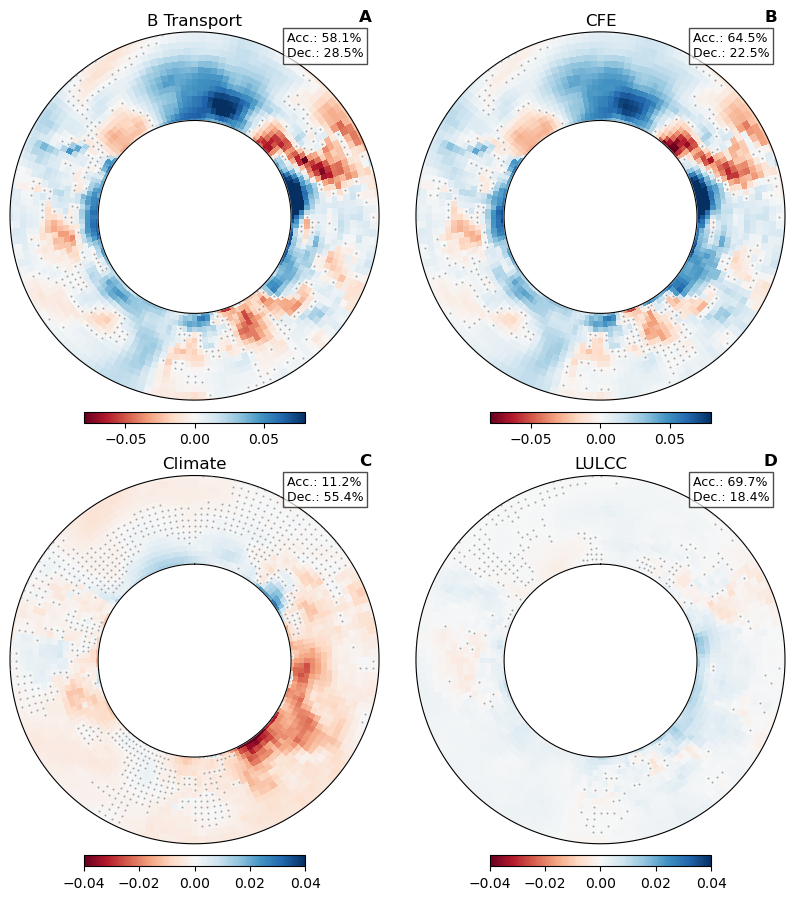

In [13]:
exp_idx = [0, 1, 2, 3] # 对应 ['B Transport', 'CFE', 'CLIM', 'LULCC']
alpha = 0.7
vmax_value = [0.08, 0.08, 0.04, 0.04]
lat_min, lat_max = 20, 50 # 更新纬度限制

fig = plt.figure(figsize=(10, 11))
gs = gridspec.GridSpec(2, 2, width_ratios=[1]*2, height_ratios=[1]*2, wspace=0.1, hspace=0.1)
axs = np.empty((2, 2), dtype=object)
for i in range(2):
    for j in range(2):
        ax = axs[i, j]
        ax = fig.add_subplot(gs[i, j], projection=ccrs.NorthPolarStereo(central_longitude=0))
        ax.set_extent([-180, 180, lat_min, lat_max], crs=ccrs.PlateCarree())
        # ax.coastlines(resolution='110m', linewidth=0.5)
        # ax.add_feature(cfeature.BORDERS, linewidth=0.5)
        theta = np.linspace(0, 2*np.pi, 240)
        r = 0.5
        verts = np.vstack([0.5 + r*np.cos(theta), 0.5 + r*np.sin(theta)]).T
        circle_path = mpath.Path(verts)
        ax.set_boundary(circle_path, transform=ax.transAxes)
        axs[i, j] = ax

for n_e, exp in enumerate(exp_list[exp_idx]):
    info = model_dict['Trendy']
    ax = axs[n_e // 2, n_e % 2]
    # 直接使用 exp 作为标题
    ax.text(0.5, 1.01, exp, transform=ax.transAxes, ha='center', va='bottom', fontsize=12)
    
    lon = info['lon']
    full_lat = info['lat']
    diff_grid = info['diff_grid'][exp_idx[n_e]]
    sign_grid = info['sign_grid'][exp_idx[n_e]]
    p_diff_grid = info['p_diff_grid'][exp_idx[n_e]]
    
    # 找到 20-50 度的索引
    lat_indices = np.where((full_lat >= lat_min) & (full_lat <= lat_max))[0]
    if len(lat_indices) == 0:
        continue
    start_idx, end_idx = lat_indices[0], lat_indices[-1] + 1
    lat = full_lat[start_idx:end_idx]

    trend_data = diff_grid[:, start_idx:end_idx, :].mean(axis=0)
    sign_start = sign_grid[start_idx:end_idx]
    p_value = p_diff_grid[start_idx:end_idx]

    mask = np.where(np.logical_or(p_value > 0.1, sign_start < 0), 1, np.nan)  # 显著性掩码
    all_mask = mask.copy()
    area = cal_area_grid(lat, lon)
    
    # 标注加速/减速百分比
    acc_percent = 0
    dec_percent = 0
    total_count = 0
    for i in range(trend_data.shape[0]):
        for j in range(trend_data.shape[1]):
            total_count += area[i, j]
            if np.logical_and(p_value[i, j] <= 0.1, sign_start[i, j] > 0):
                if trend_data[i, j] >= 0:
                    acc_percent += area[i, j]
                elif trend_data[i, j] < 0:
                    dec_percent += area[i, j]
    total_percent = acc_percent + dec_percent
    if total_count > 0:
        acc_percent = acc_percent / total_count * 100
        dec_percent = dec_percent / total_count * 100
    ax.text(0.75, 1, f'Acc.: {acc_percent:.1f}%\nDec.: {dec_percent:.1f}%', 
            transform=ax.transAxes, ha='left', va='top', fontsize=9,
            bbox=dict(boxstyle='square', facecolor='white', alpha=alpha, 
                        edgecolor='black', linestyle='-'))

    # 绘图
    im = ax.pcolormesh(lon, lat, trend_data, cmap='RdBu', vmin=-vmax_value[n_e], vmax=vmax_value[n_e], 
                        transform=ccrs.PlateCarree())

    # 标注不显著区域
    mask_points = np.isfinite(all_mask) & (all_mask == 1)
    if np.any(mask_points):
        lon2d, lat2d = np.meshgrid(lon, lat)
        ax.scatter(lon2d[mask_points], lat2d[mask_points],
                    s=2, c='gray', marker='o', alpha=alpha,
                    transform=ccrs.PlateCarree(), zorder=5, linewidths=0, rasterized=True)

    circle_lon = np.linspace(-180, 180, 200)
    # 使用 ax.fill 替代 ax.fill_between 以避免兼容性问题
    ax.fill(np.concatenate([circle_lon, circle_lon[::-1]]), 
            np.concatenate([np.full_like(circle_lon, lat_max), np.full_like(circle_lon, 90)]), 
            color='white', transform=ccrs.PlateCarree(), zorder=6)
    # 画上内边界线
    ax.plot(circle_lon, np.full_like(circle_lon, lat_max), 
            color='black', linewidth=0.8, transform=ccrs.PlateCarree(), zorder=6)
    
    cbar_ax = inset_axes(ax, width="60%", height="3%", loc='lower center',
                         bbox_to_anchor=(0, -0.08, 1, 1), bbox_transform=ax.transAxes)
    cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')

letters = ['A', 'B', 'C', 'D']
for i in range(2):
    for j in range(2):
        axs[i, j].text(0.98, 1.02, letters[i*2+j], va='bottom', ha='right',
                       fontsize=12, transform=axs[i, j].transAxes, fontweight='bold')
        
fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-5-B-to-T-map.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)

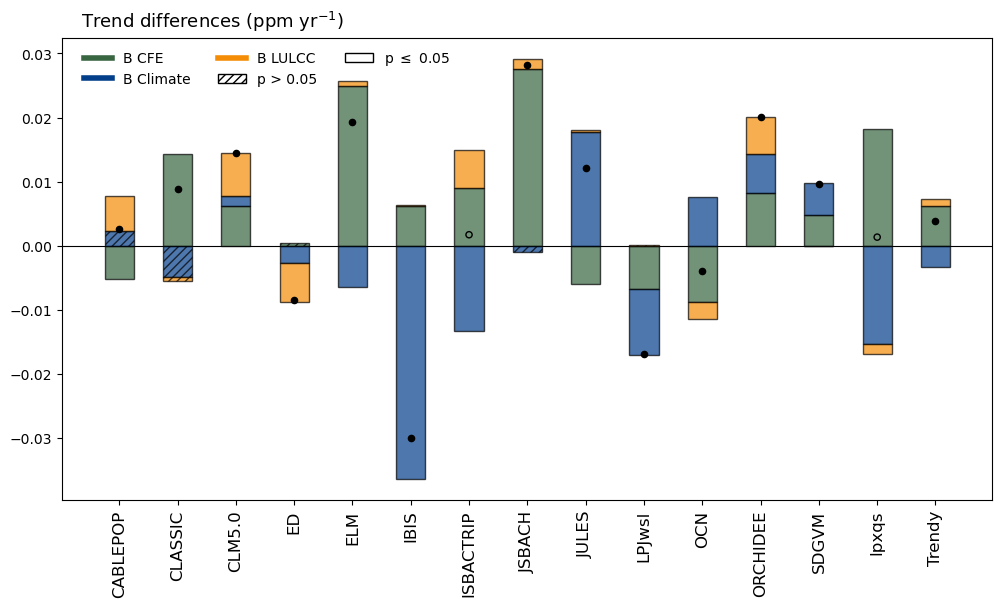

In [ ]:
# plot bar
exp_bar = ['B CFE', 'B Climate', 'B LULCC']
color_list = [
    '#386641', # B CFE 
    '#023e8a', # B Clim 
    '#f48c06', # B LULCC
]
n_exp = len(exp_bar)
n_models = len(model_dict.keys())
bar_mean = np.zeros((n_exp, n_models))
bar_std = np.zeros((n_exp, n_models))
p_vals = np.ones((n_exp, n_models))
sig_vals = np.ones((n_exp, n_models))


for n_m, (model, info) in enumerate(model_dict.items()):
    diff_region = info['diff_region']
    sign_region = info['sign_region']
    p_diff_region = info['p_diff_region']

    bar_mean[:, n_m] = np.mean(diff_region[1:], axis=-1)
    bar_std[:, n_m] = np.std(diff_region[1:], axis=-1)
    p_vals[:, n_m] = p_diff_region[1:]
    sig_vals[:, n_m] = sign_region[1:]

fig, ax = plt.subplots(figsize=(12, 6))

x_data = np.arange(n_models)
bottom_pos = np.zeros(n_models)
bottom_neg = np.zeros(n_models)

for n_e, exp in enumerate(exp_bar):
    y_data = bar_mean[n_e]
    y_err = bar_std[n_e]
    p_data = p_vals[n_e]
    # 根据 y 值的正负选择对应的底线
    bottom = np.where(y_data > 0, bottom_pos, bottom_neg)
    
    bars = ax.bar(x_data, y_data, bottom=bottom, label=exp, 
                color=color_list[n_e], width=0.5,
                edgecolor='black', linewidth=1, alpha=0.7)

    for idx, rect in enumerate(bars):
        if p_data[idx] > 0.05:
            rect.set_hatch('////')

    # 更新底线
    bottom_pos += np.maximum(y_data, 0)
    bottom_neg += np.minimum(y_data, 0)

y_control = np.array([np.mean(diff_region[0], axis=-1) for diff_region in [model_dict[model]['diff_region'] for model in model_dict]])
p_control = np.array([p_diff_region[0] for p_diff_region in [model_dict[model]['p_diff_region'] for model in model_dict]])
sig_mask = p_control <= 0.1
nosig_mask = p_control > 0.1
ax.scatter(x_data[sig_mask], y_control[sig_mask], color='black', marker='o', s=20, zorder=5)
ax.scatter(x_data[nosig_mask], y_control[nosig_mask], facecolors='none', 
           edgecolors='black', marker='o', s=20, zorder=5)

ax.axhline(0, color='black', linewidth=0.8, zorder=0)
custom_lines = [Line2D([0], [0], color=color_list[i], lw=4) for i in range(n_exp)]
custom_lines.append(mpatches.Patch(facecolor='white', edgecolor='black', hatch='////', linewidth=1))
custom_lines.append(mpatches.Patch(facecolor='white', edgecolor='black', linewidth=1))

ax.legend(custom_lines, exp_bar+['p > 0.05', 'p $\leq$ 0.05'], bbox_to_anchor=(0.01, 1), 
          loc='upper left', ncol=3, frameon=False, fontsize=10)
ax.set_xticks(x_data)
ax.set_xticklabels(list(model_dict.keys()), fontsize=12, rotation=90)
ax.text(0.02, 1.01, 'Trend differences (ppm yr$^{-1}$)', transform=ax.transAxes, ha='left', va='bottom', fontsize=13)

fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-5-B-to-T-bar.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)